# Django 4 Testing — Complete Learning Guide

This notebook is a self-contained learning resource covering Django's testing ecosystem from first principles through advanced test patterns, fixtures, and full integration testing.

---

## Prerequisites

- Python 3.10+
- Django 4.2 installed (`pip install django`)
- Basic Django familiarity (models, views, URL routing, forms)
- Basic understanding of Python classes and inheritance

---

## Learning Objectives

By the end of this course you will be able to:

1. Explain the Test Driven Development (TDD) methodology and its benefits.
2. Describe the TDD red-green-refactor cycle.
3. Distinguish between Django's `SimpleTestCase`, `TestCase`, `TransactionTestCase`, and `LiveServerTestCase`.
4. Write unit tests for models, forms, views, and custom functions.
5. Use Django's test `Client` and `RequestFactory` to test views.
6. Manage test data using `setUp`, inline creation, and fixtures.
7. Run tests with coverage tooling and interpret coverage reports.
8. Write transaction-aware tests using `TransactionTestCase`.
9. Perform full integration tests with `LiveServerTestCase` and Selenium.
10. Apply best practices for deterministic, maintainable tests.

---

## Table of Contents

1. [Test Driven Development (TDD)](#1-test-driven-development-tdd)
2. [Django Testing Tools Overview](#2-django-testing-tools-overview)
3. [The Test Case Class Hierarchy](#3-the-test-case-class-hierarchy)
4. [Code Coverage](#4-code-coverage)
5. [Incremental Improvement Strategy](#5-incremental-improvement-strategy)
6. [What Should Be Tested](#6-what-should-be-tested)
7. [Testing Models](#7-testing-models)
8. [Testing Forms](#8-testing-forms)
9. [Testing Views — with Client](#9-testing-views--with-client)
10. [Testing Views — with RequestFactory](#10-testing-views--with-requestfactory)
11. [Testing Views — with LiveServerTestCase](#11-testing-views--with-liveservertestcase)
12. [Testing Best Practices](#12-testing-best-practices)
13. [Managing Test Data](#13-managing-test-data)
14. [Working with Fixtures](#14-working-with-fixtures)
15. [Transaction Tests — TransactionTestCase](#15-transaction-tests--transactiontestcase)
16. [Full Integration Testing with Selenium](#16-full-integration-testing-with-selenium)
17. [Final Coverage Check and Workflow](#17-final-coverage-check-and-workflow)
18. [Reference Tables](#18-reference-tables)
19. [Exercises and Knowledge Checks](#19-exercises-and-knowledge-checks)
20. [Final Assessment](#20-final-assessment)

---

In [1]:
from pathlib import Path
from IPython.display import Image, display

def render_diagram(image_path, width=900):
    display(Image(filename=str(image_path), width=width))

print("Setup complete. render_diagram() is ready.")

Setup complete. render_diagram() is ready.


---
## 1. Test Driven Development (TDD)

### 1.1 What is TDD?

**Test Driven Development (TDD)** is a software development methodology where you write tests *before* you write the implementation code. Each small cycle of work follows three steps:

1. **Red** — Write a test that describes a requirement. Run it and watch it fail (it must fail, because the code doesn't exist yet).
2. **Green** — Write the *minimum* amount of code necessary to make the test pass.
3. **Refactor** — Clean up the code while keeping all tests green.

This loop is sometimes called the **Red-Green-Refactor cycle**.

### 1.2 Benefits of TDD

| Benefit | Description |
|---------|-------------|
| **Immediate feedback** | You know instantly whether a change breaks existing behaviour |
| **Code confidence** | A comprehensive test suite gives you confidence to refactor and extend |
| **Design improvement** | Writing tests first forces you to think about the API before the implementation |
| **Living documentation** | Tests describe *intended* behaviour — they serve as always-up-to-date documentation |
| **Continuous deployment** | A reliable test suite is a prerequisite for automated CI/CD pipelines |

### 1.3 The Red-Green-Refactor cycle step by step

```
┌──────────────────────────────────────────────────────┐
│                   TDD Cycle                          │
│                                                      │
│   1. Write Test  ──►  2. Watch Failure  (RED)        │
│          ▲                    │                      │
│          │                    ▼                      │
│   5. Refactor  ◄──  3. Write Minimum Code            │
│          │                    │                      │
│          │                    ▼                      │
│          └──────────  4. Run Suite  (GREEN)          │
│                                    │                 │
│                                    ▼                 │
│                        Continuous Deployment         │
└──────────────────────────────────────────────────────┘
```

### 1.4 TDD in practice

A concrete Django example — implementing an `is_even` utility:

**Step 1 — Write the test (RED):**
```python
# myapp/tests.py
from django.test import SimpleTestCase
from .utils import is_even

class IsEvenTest(SimpleTestCase):
    def test_even_number_returns_true(self):
        self.assertTrue(is_even(10))

    def test_odd_number_returns_false(self):
        self.assertFalse(is_even(7))
```

Running this now gives `ImportError` — the function doesn't exist yet. That's the **red** state.

**Step 2 — Write minimum code (GREEN):**
```python
# myapp/utils.py
def is_even(n):
    return n % 2 == 0
```

Now the tests pass — the **green** state.

**Step 3 — Refactor:**
The function is already minimal; no refactoring needed this cycle.

---
## 2. Django Testing Tools Overview

Django ships with a comprehensive testing framework built on top of Python's standard `unittest` library. You get test infrastructure without installing anything extra.

### 2.1 What Django provides out of the box

| Tool | Location | Purpose |
|------|----------|---------|
| `TestCase` | `django.test` | Database-backed tests with transaction rollback |
| `SimpleTestCase` | `django.test` | Tests that don't need a database |
| `TransactionTestCase` | `django.test` | Tests that require real database transactions |
| `LiveServerTestCase` | `django.test` | Tests that need a real HTTP server |
| `Client` | `django.test` | HTTP client for simulating browser requests |
| `RequestFactory` | `django.test` | Factory for creating WSGI request objects |
| `override_settings` | `django.test` | Decorator/context manager to change settings per test |

### 2.2 Running tests

```bash
# Run all tests in the project
python manage.py test

# Run tests in a specific app
python manage.py test myapp

# Run a specific test module
python manage.py test myapp.tests

# Run a specific test class
python manage.py test myapp.tests.ModelTests

# Run a single test method
python manage.py test myapp.tests.ModelTests.test_string_representation

# Run with verbose output
python manage.py test --verbosity=2
```

### 2.3 The test database

When you run `python manage.py test`, Django:
1. Creates a **fresh test database** (prefixed with `test_`, e.g., `test_mydb`).
2. Runs all migrations against it.
3. Executes your tests.
4. **Destroys the test database** when done.

This means your production or development data is never touched.

> **Tip:** Use `--keepdb` flag to preserve the test database between runs for faster iteration:
> ```bash
> python manage.py test --keepdb
> ```

---
## 3. The Test Case Class Hierarchy

Django's test classes form a hierarchy. Choosing the right class for each test is important for correctness and performance.

### 3.1 Class hierarchy

```
Python unittest.TestCase
└── django.test.SimpleTestCase
    └── django.test.TransactionTestCase
        └── django.test.TestCase
            └── django.test.LiveServerTestCase
```

### 3.2 Choosing the right class

| Class | Database | Transactions | When to use |
|-------|----------|-------------|-------------|
| `SimpleTestCase` | No | No | Pure logic, utility functions, template rendering without DB |
| `TransactionTestCase` | Yes | Real | When you need to test actual DB transaction behaviour (e.g., rollbacks, `select_for_update`) |
| `TestCase` | Yes | Wrapped (rollback) | The default choice for model/form/view tests |
| `LiveServerTestCase` | Yes | Wrapped (rollback) | Full browser integration tests using Selenium or Playwright |

> **Rule of thumb:** Start with `TestCase`. Only switch to `TransactionTestCase` if your test requires real transaction commits/rollbacks. Only switch to `LiveServerTestCase` if you need a real browser.

### 3.3 Basic test class skeleton

```python
# myapp/tests.py
from django.test import TestCase
from .models import MyModel

class GenericTest(TestCase):

    def setUp(self):
        # Runs before EACH test method
        MyModel.objects.create(name='TestName')

    def test_generic_feature(self):
        obj = MyModel.objects.get(name='TestName')
        self.assertEqual(obj.name, 'TestName')
```

### 3.4 Django's additional test helpers

| Helper | Purpose |
|--------|----------|
| `self.client` | Pre-configured `Client` instance available in every `TestCase` |
| `self.assertContains(response, text)` | Assert that an HTTP response contains a given text |
| `self.assertRedirects(response, url)` | Assert that an HTTP response redirects to a URL |
| `self.assertTemplateUsed(response, template)` | Assert that a specific template was used |
| `self.assertFormError(response, form, field, errors)` | Assert that a form field has a specific error |

---
## 4. Code Coverage

### 4.1 What is code coverage?

Code coverage measures what percentage of your source code is executed when your test suite runs. High coverage doesn't guarantee bug-free code, but low coverage is a strong signal that large parts of the system are untested.

### 4.2 Installing and using `coverage`

```bash
pip install coverage
```

**Run tests with coverage measurement:**
```bash
coverage run --source='.' manage.py test
```

**View the coverage report in the terminal:**
```bash
coverage report
```

**Generate an interactive HTML report:**
```bash
coverage html
# Then open htmlcov/index.html in your browser
```

### 4.3 Example coverage report output

```
Name                      Stmts   Miss  Cover
---------------------------------------------
myapp/__init__.py             0      0   100%
myapp/models.py              12      0   100%
myapp/forms.py               18      2    89%
myapp/views.py               34      8    76%
myapp/utils.py                6      0   100%
---------------------------------------------
TOTAL                        70     10    86%
```

### 4.4 `.coveragerc` configuration

Create a `.coveragerc` file at the project root to configure coverage:

```ini
[run]
source = .
omit =
    */migrations/*
    */tests/*
    manage.py
    */settings/*

[report]
show_missing = True
skip_covered = False
```

### 4.5 Coverage targets

| Coverage % | Signal |
|-----------|--------|
| < 50% | Large portions of the codebase are untested — risky |
| 50–75% | Basic coverage; important paths may be missing |
| 75–90% | Good coverage for most projects |
| > 90% | Thorough — aim for this for critical applications |
| 100% | All lines executed; does not mean all *behaviours* are tested |

> **Important:** 100% line coverage does not mean 100% branch coverage. A line can be covered without testing all its conditional paths. Use `coverage run --branch` for branch coverage.

---
## 5. Incremental Improvement Strategy

### 5.1 The incremental approach

Rather than trying to implement and test entire features at once, TDD encourages an incremental cycle:

### 5.2 Incremental improvement cycle

Rather than trying to implement and test entire features at once, TDD encourages an incremental cycle:

```
Small Requirement
       │
       ▼
Test Development  ◄──────────────┐
       │                         │
       ▼                         │
   Write Code                    │
       │                         │
       ▼                         │
Expand Requirement               │
       │                         │
       ▼                         │
Integration Test Development     │
       │                         │
       ▼                         │
   Add Code  ────────────────────┘
```

### 5.3 Applying incremental improvements

1. **Start small** — pick the simplest behaviour to test first.
2. **Test one thing per test** — each test method should verify exactly one assertion or one behaviour.
3. **Expand gradually** — once the simple case passes, add edge cases and integration tests.
4. **Check coverage after each cycle** — use coverage reports to guide where to write tests next.

```python
# Iteration 1 — simple case
class CommentModelTest(TestCase):
    def test_comment_can_be_created(self):
        comment = Comment.objects.create(name='Alice', email='alice@x.com', message='Hello')
        self.assertIsNotNone(comment.pk)

# Iteration 2 — expand with string representation
    def test_str_representation(self):
        comment = Comment(name='Alice')
        self.assertEqual(str(comment), 'Comment by Alice')

# Iteration 3 — expand with field constraints
    def test_name_max_length(self):
        max_length = Comment._meta.get_field('name').max_length
        self.assertEqual(max_length, 100)
```

---
## 6. What Should Be Tested

### 6.1 The four testing targets in Django

Django tests typically target four areas:

### 6.2 Testing targets overview

| Target | What to test | Django class to use |
|--------|-------------|--------------------|
| **Models** | Field constraints, `__str__`, custom methods, manager methods, signals | `TestCase` |
| **Forms** | Validation logic, `clean_*` methods, required fields, error messages | `TestCase` (or `SimpleTestCase` if no DB) |
| **Views** | Status codes, template used, context data, redirects, CRUD behaviour | `TestCase` with `Client` or `RequestFactory` |
| **Other / Custom code** | Utility functions, helper methods, custom validators, signal handlers | `SimpleTestCase` or `TestCase` |

### 6.3 Prioritising what to test

Not all code is equally important to test. Prioritise:

1. **Business logic** — the unique rules your application enforces (custom `clean()` methods, model managers, utility functions).
2. **Boundary conditions** — empty strings, zero, negative numbers, maximum values.
3. **Error paths** — what happens when validation fails, when a record doesn't exist, when permissions are denied.
4. **Happy path** — the normal, expected flow that users follow.
5. **Boilerplate paths** — standard CRUD operations that follow Django's conventions.

### 6.4 What not to test

Avoid testing:
- Django's own built-in validators and middleware (they are already tested by Django's own test suite).
- Third-party library internals.
- Infrastructure concerns (database connections, network availability) in unit tests.

---
## 7. Testing Models

### 7.1 What to test in a model

- Field constraints (`max_length`, `blank`, `null`, `unique`, `default`)
- The `__str__` method
- Custom model methods
- Custom manager methods
- Model properties

### 7.2 Example model

```python
# myapp/models.py
from django.db import models

class Article(models.Model):
    title      = models.CharField(max_length=200)
    body       = models.TextField()
    published  = models.BooleanField(default=False)
    created_at = models.DateTimeField(auto_now_add=True)

    def __str__(self):
        return self.title

    def word_count(self):
        return len(self.body.split())
```

### 7.3 Model test skeleton

```python
# myapp/tests.py
from django.test import TestCase
from .models import Article

class ArticleModelTest(TestCase):

    def setUp(self):
        self.article = Article.objects.create(
            title='Test Article',
            body='This is a test article body with several words.',
        )

    def test_str_representation(self):
        self.assertEqual(str(self.article), 'Test Article')

    def test_title_max_length(self):
        max_length = Article._meta.get_field('title').max_length
        self.assertEqual(max_length, 200)

    def test_default_published_is_false(self):
        self.assertFalse(self.article.published)

    def test_word_count(self):
        # 'This is a test article body with several words.' = 9 words
        self.assertEqual(self.article.word_count(), 9)

    def test_article_can_be_saved(self):
        self.assertIsNotNone(self.article.pk)

    def test_article_has_created_at(self):
        self.assertIsNotNone(self.article.created_at)
```

### 7.4 Testing field constraints

```python
class ArticleFieldTest(TestCase):

    def test_body_is_text_field(self):
        field = Article._meta.get_field('body')
        self.assertIsInstance(field, models.TextField)

    def test_published_default(self):
        field = Article._meta.get_field('published')
        self.assertFalse(field.default)
```

### 7.5 Common model test assertions

| Assertion | Checks |
|-----------|--------|
| `assertEqual(str(obj), 'expected')` | `__str__` output |
| `assertEqual(field.max_length, 200)` | Field constraint value |
| `assertIsNotNone(obj.pk)` | Object was saved to DB |
| `assertRaises(ValidationError, obj.full_clean)` | Model validation raises correctly |
| `assertIsInstance(field, models.TextField)` | Field type |
| `assertTrue(field.blank)` | Field allows blank |

In [2]:
# Conceptual demonstration of model test logic (no Django server needed)

class MockArticle:
    """Simulates a Django model for demonstration."""
    def __init__(self, title, body, published=False):
        self.title = title
        self.body = body
        self.published = published
        self.pk = id(self)

    def __str__(self):
        return self.title

    def word_count(self):
        return len(self.body.split())


# Simulate the tests
article = MockArticle(
    title='Test Article',
    body='This is a test article body with several words.',
)

results = [
    ('test_str_representation',    str(article) == 'Test Article',         'Test Article'),
    ('test_default_published',     article.published == False,             False),
    ('test_word_count',            article.word_count() == 9,              9),
    ('test_article_saved',         article.pk is not None,                 'not None'),
]

print(f"{'Test':<35} {'Pass?':<7} {'Value'}")
print("-" * 65)
for name, passed, value in results:
    status = '✓ PASS' if passed else '✗ FAIL'
    print(f"{name:<35} {status:<7} {value}")

Test                                Pass?   Value
-----------------------------------------------------------------
test_str_representation             ✓ PASS  Test Article
test_default_published              ✓ PASS  False
test_word_count                     ✓ PASS  9
test_article_saved                  ✓ PASS  not None


---
## 8. Testing Forms

### 8.1 What to test in a form

- Valid data produces a valid form (`is_valid()` returns `True`)
- Invalid data produces the correct errors
- Required fields are enforced
- Custom `clean_*` methods apply correct transformations
- Custom `clean()` cross-field validation works

### 8.2 Form test pattern

```python
# myapp/tests.py
from django.test import TestCase
from .forms import ArticleForm

class ArticleFormTest(TestCase):

    def test_valid_form(self):
        form = ArticleForm(data={
            'title': 'My Article',
            'body':  'Some body text here.',
        })
        self.assertTrue(form.is_valid())

    def test_title_required(self):
        form = ArticleForm(data={'title': '', 'body': 'Some text.'})
        self.assertFalse(form.is_valid())
        self.assertIn('title', form.errors)

    def test_body_required(self):
        form = ArticleForm(data={'title': 'My Article', 'body': ''})
        self.assertFalse(form.is_valid())
        self.assertIn('body', form.errors)

    def test_empty_form_is_invalid(self):
        form = ArticleForm(data={})
        self.assertFalse(form.is_valid())
```

### 8.3 Testing custom validation

```python
class ArticleFormValidationTest(TestCase):

    def test_reserved_title_rejected(self):
        form = ArticleForm(data={'title': 'admin', 'body': 'Some text.'})
        self.assertFalse(form.is_valid())
        self.assertIn('title', form.errors)
        self.assertIn('reserved', form.errors['title'][0].lower())

    def test_title_is_title_cased(self):
        """clean_title() should title-case the value."""
        form = ArticleForm(data={'title': 'my article', 'body': 'Some text.'})
        self.assertTrue(form.is_valid())
        self.assertEqual(form.cleaned_data['title'], 'My Article')
```

### 8.4 Testing ModelForms with `save()`

```python
from .forms import ArticleModelForm
from .models import Article

class ArticleModelFormTest(TestCase):

    def test_valid_form_saves(self):
        form = ArticleModelForm(data={
            'title': 'New Article',
            'body':  'Article body text.',
        })
        self.assertTrue(form.is_valid())
        article = form.save()
        self.assertIsNotNone(article.pk)
        self.assertEqual(Article.objects.count(), 1)

    def test_invalid_form_does_not_save(self):
        form = ArticleModelForm(data={'title': '', 'body': 'Text.'})
        self.assertFalse(form.is_valid())
        self.assertEqual(Article.objects.count(), 0)
```

---
## 9. Testing Views — with Client

### 9.1 The `Client` class

Django's `Client` class simulates a browser making HTTP requests to your application. It is the most common way to test views.

| Feature | Description |
|---------|-------------|
| `client.get(url)` | Simulate a GET request |
| `client.post(url, data)` | Simulate a POST request |
| `client.login(username=..., password=...)` | Authenticate a user |
| `response.status_code` | HTTP status code of the response |
| `response.context` | Template context dictionary |
| `response.content` | Raw response bytes |

### 9.2 View test skeleton — `Client`

```python
# myapp/tests.py
from django.test import TestCase
from .models import Article

class ArticleViewTest(TestCase):

    def setUp(self):
        self.article = Article.objects.create(
            title='Test Article',
            body='Body text.',
        )

    def test_list_view_returns_200(self):
        response = self.client.get('/articles/')
        self.assertEqual(response.status_code, 200)

    def test_list_view_uses_correct_template(self):
        response = self.client.get('/articles/')
        self.assertTemplateUsed(response, 'myapp/article_list.html')

    def test_list_view_contains_article_title(self):
        response = self.client.get('/articles/')
        self.assertContains(response, 'Test Article')

    def test_detail_view_returns_200(self):
        response = self.client.get(f'/articles/{self.article.pk}/')
        self.assertEqual(response.status_code, 200)

    def test_detail_view_returns_404_for_missing_article(self):
        response = self.client.get('/articles/9999/')
        self.assertEqual(response.status_code, 404)
```

### 9.3 Testing POST views

```python
    def test_create_view_post_creates_article(self):
        response = self.client.post('/articles/create/', {
            'title': 'New Article',
            'body':  'Body of new article.',
        })
        # Should redirect after successful creation
        self.assertEqual(response.status_code, 302)
        self.assertEqual(Article.objects.count(), 2)  # 1 from setUp + 1 created

    def test_create_view_invalid_post_rerenders_form(self):
        response = self.client.post('/articles/create/', {
            'title': '',  # Invalid — required field
            'body':  'Some body.',
        })
        self.assertEqual(response.status_code, 200)  # No redirect — form re-rendered
        self.assertFormError(response, 'form', 'title', 'This field is required.')
```

### 9.4 Using `reverse()` instead of hardcoded URLs

```python
from django.urls import reverse

class ArticleViewTest(TestCase):

    def test_list_view_returns_200(self):
        url = reverse('article-list')  # Resolves by URL name
        response = self.client.get(url)
        self.assertEqual(response.status_code, 200)
```

> **Best practice:** Always use `reverse()` instead of hardcoded URL strings. If the URL changes, only the `urls.py` file needs updating — your tests remain correct.

---
## 10. Testing Views — with RequestFactory

### 10.1 `RequestFactory` vs `Client`

`RequestFactory` creates WSGI request objects directly, bypassing URL routing and middleware. This makes it faster than `Client` but less realistic.

| Aspect | `Client` | `RequestFactory` |
|--------|----------|-------------------|
| URL routing | Resolved | Bypassed |
| Middleware | Applied | Bypassed |
| Authentication | `client.login()` | Set `request.user` directly |
| Speed | Slower | Faster |
| Realism | Higher | Lower |
| Use case | Integration-level view tests | Unit-level view function tests |

### 10.2 `RequestFactory` skeleton

```python
# myapp/tests.py
from django.test import TestCase, RequestFactory
from django.contrib.auth.models import User
from .models import Article
from .views import ArticleListView, ArticleDetailView

class ArticleViewFactoryTest(TestCase):

    def setUp(self):
        self.factory = RequestFactory()
        self.user    = User.objects.create_user(
            username='testuser',
            password='testpass123',
        )
        self.article = Article.objects.create(
            title='Test Article',
            body='Body text.',
        )

    def test_list_view(self):
        request          = self.factory.get('/articles/')
        request.user     = self.user     # Middleware is bypassed — set user manually
        response         = ArticleListView.as_view()(request)
        self.assertEqual(response.status_code, 200)

    def test_detail_view(self):
        request          = self.factory.get(f'/articles/{self.article.pk}/')
        request.user     = self.user
        response         = ArticleDetailView.as_view()(request, pk=self.article.pk)
        self.assertEqual(response.status_code, 200)
```

### 10.3 When to choose `RequestFactory`

Use `RequestFactory` when:
- You want to test a view function or class in isolation, without Django's middleware.
- You need to inject a specific `request.user` or `request.session` without going through the auth middleware.
- You are unit-testing a view and middleware correctness is not your concern.

Use `Client` when:
- You want to test the full request-response cycle, including middleware (CSRF, auth, sessions).
- You are writing integration tests that verify URLs, redirects, and templates together.

---
## 11. Testing Views — with LiveServerTestCase

### 11.1 What is `LiveServerTestCase`?

`LiveServerTestCase` spins up a real Django development server on a random port before the test class runs. This lets external tools — like Selenium or Playwright — interact with your application exactly as a browser would.

### 11.2 When to use `LiveServerTestCase`

Use it for:
- JavaScript-driven interactions that can't be tested with `Client` (e.g., dynamic filtering, AJAX form submission).
- End-to-end UI tests that verify the full stack from browser to database.
- Tests that require a real HTTP server URL.

### 11.3 Selenium + `LiveServerTestCase` skeleton

First, install Selenium:
```bash
pip install selenium
```

```python
# myapp/tests.py
from django.test import LiveServerTestCase
from selenium import webdriver
from selenium.webdriver.common.by import By
from selenium.webdriver.support.ui import WebDriverWait
from selenium.webdriver.support import expected_conditions as EC

class ArticleLiveTest(LiveServerTestCase):

    @classmethod
    def setUpClass(cls):
        super().setUpClass()
        options = webdriver.ChromeOptions()
        options.add_argument('--headless')      # Run without opening a browser window
        options.add_argument('--no-sandbox')
        cls.selenium = webdriver.Chrome(options=options)
        cls.selenium.implicitly_wait(10)

    @classmethod
    def tearDownClass(cls):
        cls.selenium.quit()
        super().tearDownClass()

    def test_article_list_page_loads(self):
        self.selenium.get(f'{self.live_server_url}/articles/')
        heading = self.selenium.find_element(By.TAG_NAME, 'h1')
        self.assertIsNotNone(heading)

    def test_article_form_submission(self):
        self.selenium.get(f'{self.live_server_url}/articles/create/')
        self.selenium.find_element(By.NAME, 'title').send_keys('Selenium Article')
        self.selenium.find_element(By.NAME, 'body').send_keys('Written by Selenium.')
        self.selenium.find_element(By.CSS_SELECTOR, 'button[type=submit]').click()
        # After valid submission, should redirect to list
        WebDriverWait(self.selenium, 5).until(
            EC.url_contains('/articles/')
        )
        self.assertIn('Selenium Article', self.selenium.page_source)
```

### 11.4 Key points for `LiveServerTestCase`

- `self.live_server_url` contains the full URL (e.g., `http://localhost:54321`).
- Use `setUpClass` / `tearDownClass` for the browser driver — it is expensive to create per test.
- Use headless mode for CI environments.
- `LiveServerTestCase` is slower than `TestCase` — reserve it for high-value end-to-end scenarios.

---
## 12. Testing Best Practices

### 12.2 Core best practices

| Principle | Description |
|-----------|-------------|
| **Keep tests small** | Each test method should verify exactly one behaviour. Long tests are hard to read and hard to diagnose when they fail. |
| **Avoid too much logic in tests** | Tests should contain assertions, not business logic. If you find yourself writing `if` statements in a test, split it into multiple tests. |
| **Deterministic tests** | A test must produce the same result every time it runs. Avoid time-dependent logic (`datetime.now()`), random numbers, or network calls. |
| **Keep assertions simple** | One assertion per test is a good guideline. If you need multiple, they should all be about the same behaviour. |
| **Name your tests well** | Test names should read like sentences: `test_empty_title_raises_validation_error`. |
| **Check coverage often** | Run coverage regularly to spot untested code before it accumulates. |

### 12.3 Naming conventions

```python
# Good test names — describe the scenario and expected outcome
def test_valid_form_passes_validation(self):
def test_empty_title_fails_validation(self):
def test_list_view_returns_200_for_anonymous_user(self):
def test_admin_can_delete_article(self):
def test_word_count_returns_zero_for_empty_body(self):

# Poor test names — too vague
def test_form(self):           # What about the form?
def test_view_1(self):         # Which view? What scenario?
def test_model_ok(self):       # "ok" tells you nothing
```

### 12.4 Avoiding non-determinism

```python
from unittest.mock import patch
from datetime import datetime

class ArticleTimestampTest(TestCase):

    @patch('myapp.models.datetime')
    def test_created_at_is_set_on_creation(self, mock_dt):
        # Freeze time so the test is deterministic
        mock_dt.now.return_value = datetime(2024, 1, 15, 12, 0, 0)
        article = Article.objects.create(title='Test', body='Body')
        self.assertEqual(article.created_at.date(), datetime(2024, 1, 15).date())
```

### 12.5 Isolating tests from each other

Django's `TestCase` wraps each test in a transaction that is rolled back after the test. This means:
- Database changes in one test do NOT affect other tests.
- You can create objects in `setUp` without worrying about cleanup.
- Tests can run in any order.

```python
class IsolatedTest(TestCase):

    def test_a_creates_object(self):
        Article.objects.create(title='A', body='B')
        self.assertEqual(Article.objects.count(), 1)

    def test_b_starts_fresh(self):
        # The object created in test_a is rolled back
        self.assertEqual(Article.objects.count(), 0)
```

---
## 13. Managing Test Data

### 13.1 Three strategies for test data

Django gives you three ways to provide test data, each with distinct tradeoffs:

| Strategy | When to use | Advantage | Disadvantage |
|----------|------------|-----------|-------------|
| **Create in the test method** | Testing the creation itself; one-off data | Simple, self-contained | Repetitive if many tests need the same data |
| **Create in `setUp`** | Shared data needed by multiple tests in the class | No repetition within the class | Adds DB overhead for tests that don't need it |
| **Fixtures** | Large, stable datasets; shared across multiple test classes | Centrally managed; can be loaded from real data | Harder to maintain if models change |

### 13.2 Strategy 1 — Create data inline in the test

```python
class InlineDataTest(TestCase):

    def test_comment_creation(self):
        # Data lives only in this test
        comment = Comment.objects.create(
            name='Alice',
            email='alice@example.com',
            message='Hello world',
        )
        self.assertEqual(comment.name, 'Alice')
```

Use this when the data itself is what the test is about (e.g., testing a custom `create` method).

### 13.3 Strategy 2 — Create data in `setUp`

```python
class SetupDataTest(TestCase):

    def setUp(self):
        # Runs before EACH test — all tests in this class share this data
        self.comment = Comment.objects.create(
            name='Alice',
            email='alice@example.com',
            message='Hello world',
        )

    def test_comment_name(self):
        comment = Comment.objects.get(pk=self.comment.pk)
        self.assertEqual(comment.name, self.comment.name)

    def test_comment_email(self):
        self.assertEqual(self.comment.email, 'alice@example.com')
```

> **Note:** `setUp` runs before **each** test method. If you have 10 test methods, Django creates and rolls back the object 10 times. This is usually fast enough, but for large datasets consider using `setUpTestData()` which runs once per class.

### 13.4 Using `setUpTestData()` for class-level data

```python
class EfficientDataTest(TestCase):

    @classmethod
    def setUpTestData(cls):
        # Runs ONCE for the entire test class — much faster for large datasets
        cls.comment = Comment.objects.create(
            name='Alice',
            email='alice@example.com',
            message='Hello world',
        )

    def test_comment_name(self):
        self.assertEqual(self.comment.name, 'Alice')
```

> **Warning:** Objects created in `setUpTestData()` are shared across all test methods. Do not modify them — changes will persist to the next test. If you need to modify an object, use `setUp()` instead.

---
## 14. Working with Fixtures

### 14.1 What are fixtures?

Fixtures are files (JSON, YAML, or XML) that contain pre-defined database records. Django can load them into the test database before your tests run.

### 14.2 Creating a fixture

**Option A — Dump existing data:**
```bash
# After creating objects in the shell or admin, export them:
python manage.py dumpdata myapp.Comment --indent 2 > myapp/fixtures/comments.json
```

**Option B — Write the fixture manually:**
```json
// myapp/fixtures/comments.json
[
    {
        "model": "myapp.comment",
        "pk": 1,
        "fields": {
            "name": "Alice",
            "email": "alice@example.com",
            "message": "Hello world"
        }
    },
    {
        "model": "myapp.comment",
        "pk": 2,
        "fields": {
            "name": "Bob",
            "email": "bob@example.com",
            "message": "Another comment"
        }
    }
]
```

### 14.3 Using fixtures in tests

```python
from django.test import TestCase
from .models import Comment

class FixtureTest(TestCase):
    fixtures = ['comments.json']   # Django looks in <app>/fixtures/ by default

    def setUp(self):
        # You can combine fixtures with additional setUp data
        self.extra = Comment.objects.create(
            name='Charlie',
            email='charlie@example.com',
            message='Extra comment',
        )

    def test_fixture_data_loaded(self):
        # 2 from fixture + 1 from setUp = 3
        self.assertEqual(Comment.objects.count(), 3)

    def test_alice_comment_exists(self):
        alice = Comment.objects.get(name='Alice')
        self.assertEqual(alice.email, 'alice@example.com')
```

### 14.4 Fixture file locations

Django searches for fixtures in:
1. `<app>/fixtures/`
2. Any directory listed in `FIXTURE_DIRS` in `settings.py`

```python
# settings.py
FIXTURE_DIRS = [
    BASE_DIR / 'fixtures',   # Project-level fixtures directory
]
```

### 14.5 Loading fixtures manually

```bash
# Load a fixture into the current database (development or staging)
python manage.py loaddata comments.json
```

### 14.6 Fixture tradeoffs

| Advantage | Disadvantage |
|-----------|-------------|
| Centralised — one file, many tests | Brittle — model changes require fixture updates |
| Can reflect real data from a dump | Hard to read for large datasets |
| Faster for bulk data than `setUp` | PKs may conflict between test classes |
| Shareable across projects | JSON format is verbose |

In [3]:
# Demonstrate fixture JSON structure (no Django needed)
import json

fixture_data = [
    {
        "model": "myapp.comment",
        "pk": 1,
        "fields": {
            "name": "Alice",
            "email": "alice@example.com",
            "message": "Hello world"
        }
    },
    {
        "model": "myapp.comment",
        "pk": 2,
        "fields": {
            "name": "Bob",
            "email": "bob@example.com",
            "message": "Another comment"
        }
    }
]

print("Fixture file contents (myapp/fixtures/comments.json):")
print(json.dumps(fixture_data, indent=2))
print(f"\nTotal records: {len(fixture_data)}")
for record in fixture_data:
    print(f"  PK {record['pk']}: {record['fields']['name']} — {record['fields']['message']}")

Fixture file contents (myapp/fixtures/comments.json):
[
  {
    "model": "myapp.comment",
    "pk": 1,
    "fields": {
      "name": "Alice",
      "email": "alice@example.com",
      "message": "Hello world"
    }
  },
  {
    "model": "myapp.comment",
    "pk": 2,
    "fields": {
      "name": "Bob",
      "email": "bob@example.com",
      "message": "Another comment"
    }
  }
]

Total records: 2
  PK 1: Alice — Hello world
  PK 2: Bob — Another comment


---
## 15. Transaction Tests — TransactionTestCase

### 15.1 Why transactions matter in tests

Django's `TestCase` wraps each test in a database transaction that is rolled back at the end. This is fast and keeps tests isolated, but it means the code under test never sees a real commit — so transaction-dependent behaviour (e.g., `ON COMMIT` hooks, database signals that fire post-commit, `select_for_update()` under real concurrency) cannot be tested.

### 15.2 TestCase vs TransactionTestCase

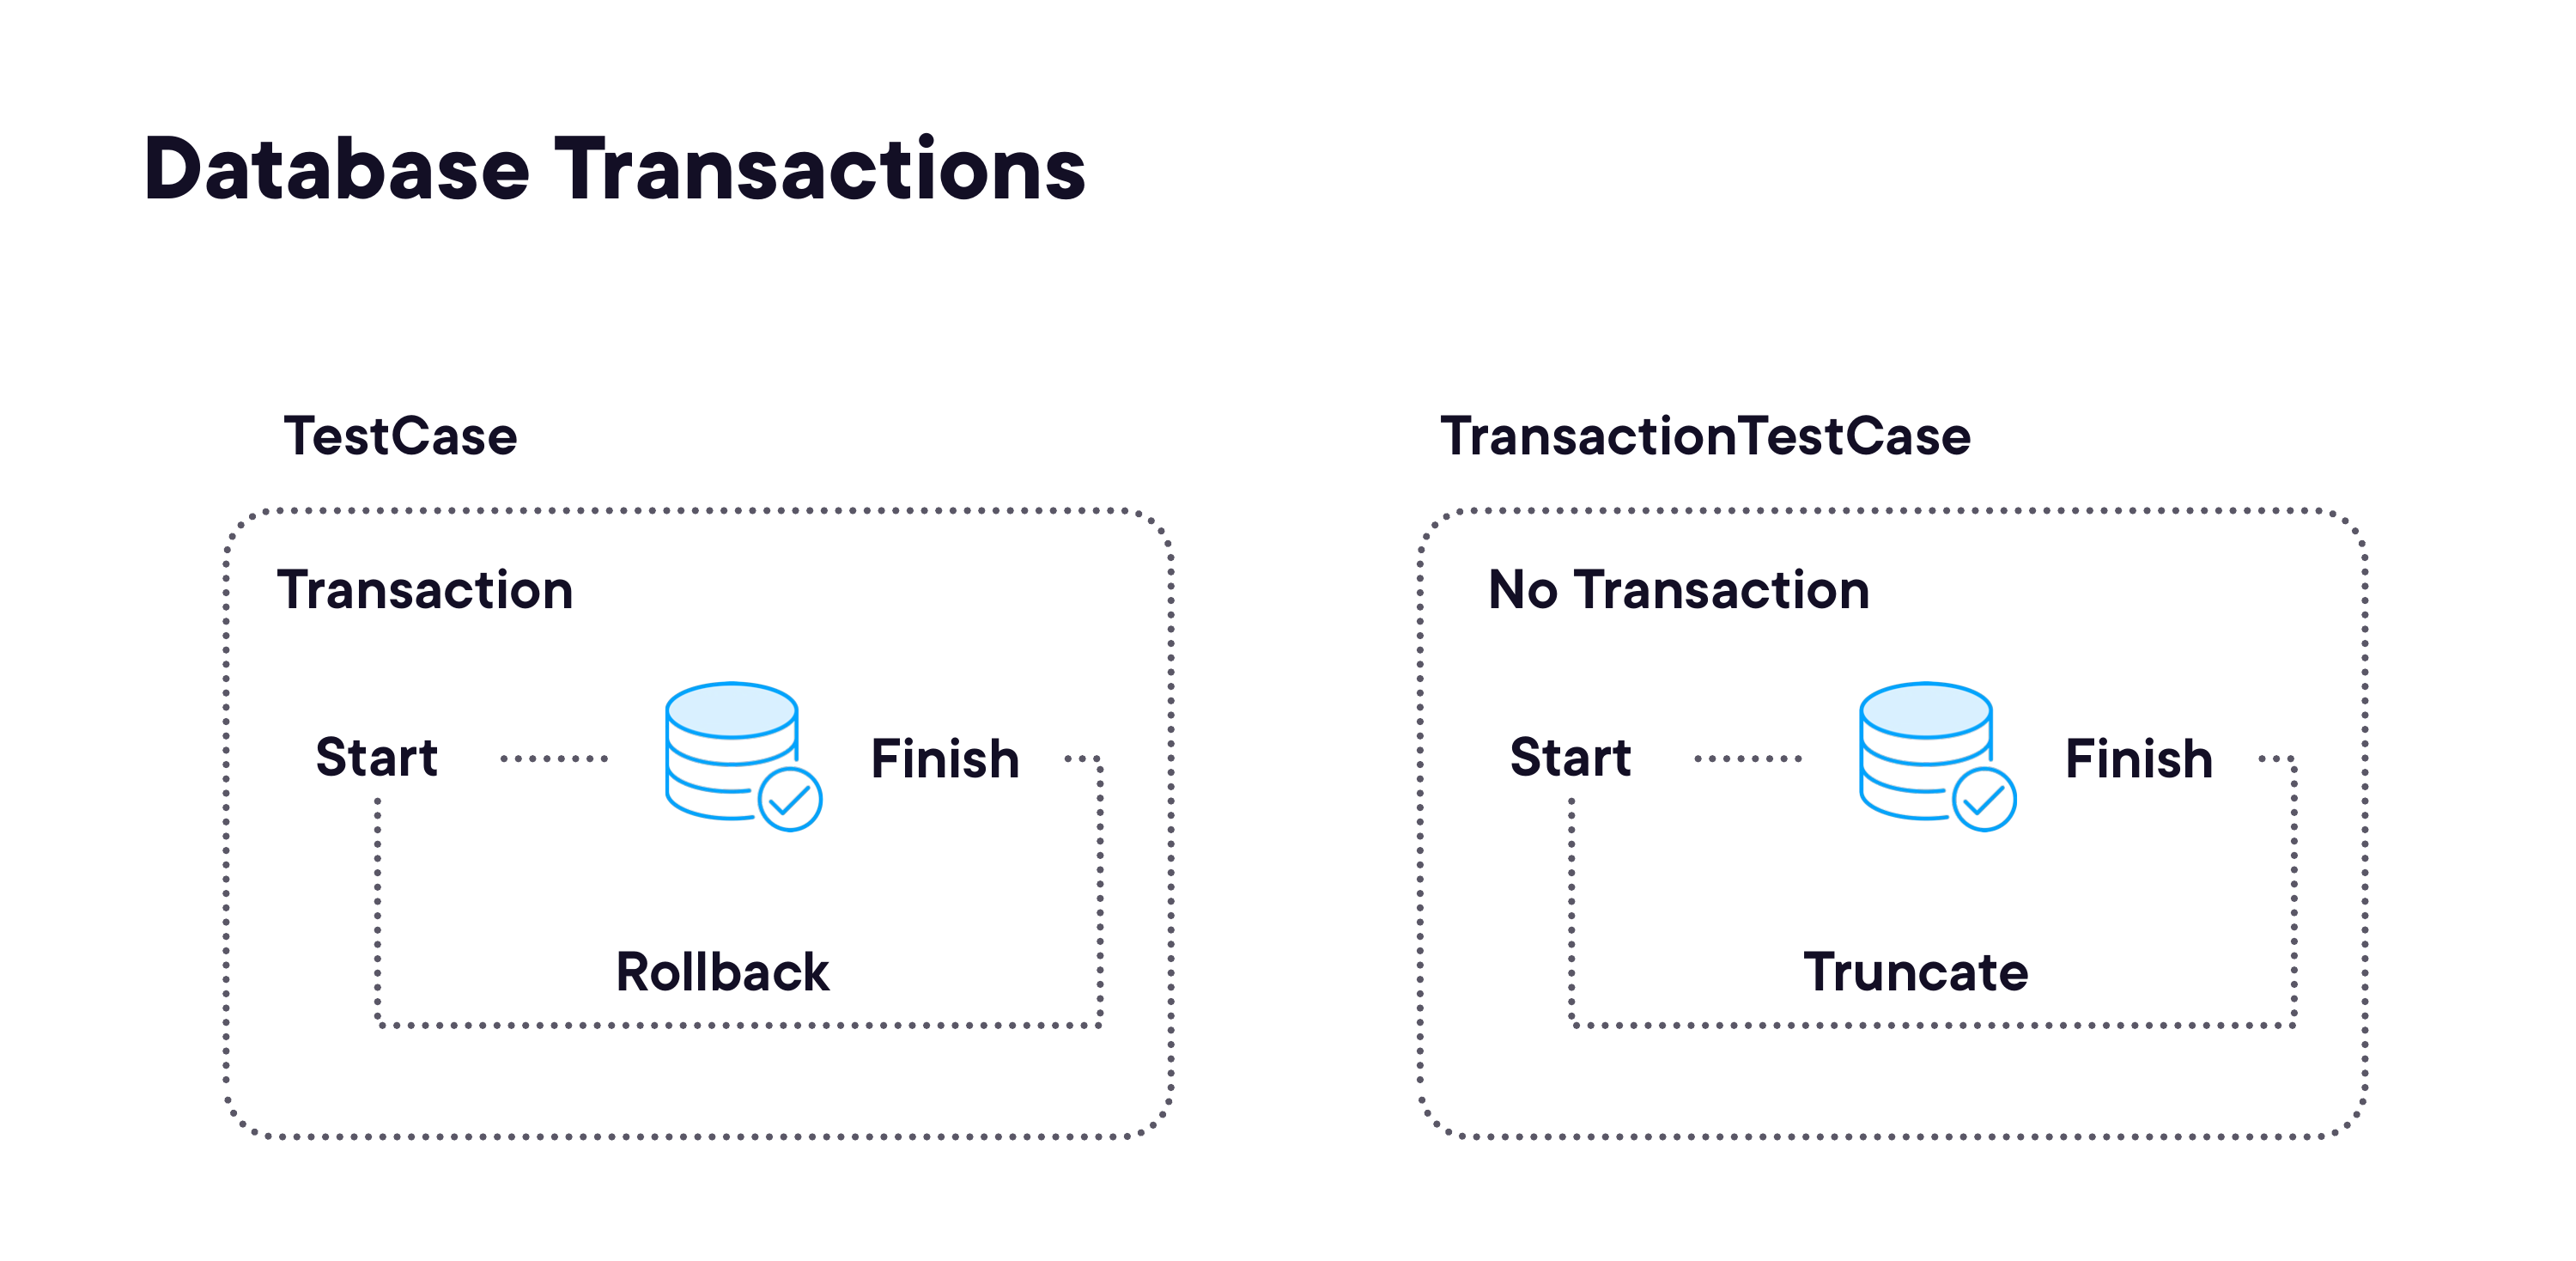

In [4]:
render_diagram("assets/transaction_comparison.png")

### 15.3 The difference — step by step

```
┌──────────────────────────────────────────────────────────────────┐
│  TestCase (wrapped transaction)                                  │
│                                                                  │
│  BEGIN TRANSACTION  ──►  setUp  ──►  test  ──►  ROLLBACK         │
│                                                                  │
│  Database never sees a committed state                           │
└──────────────────────────────────────────────────────────────────┘

┌──────────────────────────────────────────────────────────────────┐
│  TransactionTestCase (real commits)                              │
│                                                                  │
│  setUp  ──►  test  ──►  COMMIT  ──►  TRUNCATE all tables         │
│                                                                  │
│  Database sees real commits; table truncated after each test     │
└──────────────────────────────────────────────────────────────────┘
```

### 15.4 When to use `TransactionTestCase`

- Testing code that uses `transaction.on_commit()` hooks.
- Testing `select_for_update()` row locking.
- Testing database-level uniqueness in concurrent scenarios.
- Testing Celery tasks that are dispatched after a commit.

### 15.5 `TransactionTestCase` example

```python
# myapp/tests.py
from django.test import TransactionTestCase
from django.db import transaction
from .models import Article

class OnCommitTest(TransactionTestCase):

    def test_on_commit_hook_fires(self):
        called = []

        def after_commit():
            called.append(True)

        with transaction.atomic():
            Article.objects.create(title='Test', body='Body')
            transaction.on_commit(after_commit)

        # The commit has happened — the hook should have fired
        self.assertEqual(len(called), 1)
```

### 15.6 Performance warning

`TransactionTestCase` is **significantly slower** than `TestCase` because:
- It truncates (not rolls back) the database between tests.
- Table truncation is an expensive operation.
- It cannot benefit from `setUpTestData()`.

Only use `TransactionTestCase` when you genuinely need real transaction commits.

---
## 16. Full Integration Testing with Selenium

### 16.1 Setting up Selenium

```bash
pip install selenium
# For ChromeDriver (Google Chrome must be installed)
# ChromeDriver is bundled with Selenium 4.6+ — no separate download needed
```

### 16.2 Full integration test example

```python
# myapp/tests.py
from django.test import LiveServerTestCase
from django.contrib.auth.models import User
from selenium import webdriver
from selenium.webdriver.common.by import By
from selenium.webdriver.support.ui import WebDriverWait
from selenium.webdriver.support import expected_conditions as EC

class FullIntegrationTest(LiveServerTestCase):

    @classmethod
    def setUpClass(cls):
        super().setUpClass()
        options = webdriver.ChromeOptions()
        options.add_argument('--headless=new')
        options.add_argument('--no-sandbox')
        options.add_argument('--disable-dev-shm-usage')
        cls.selenium = webdriver.Chrome(options=options)
        cls.selenium.implicitly_wait(5)

    @classmethod
    def tearDownClass(cls):
        cls.selenium.quit()
        super().tearDownClass()

    def setUp(self):
        # Create a test user
        self.user = User.objects.create_superuser(
            username='admin',
            password='adminpass123',
            email='admin@test.com',
        )

    def test_login_and_create_article(self):
        # Step 1 — Navigate to login page
        self.selenium.get(f'{self.live_server_url}/admin/')

        # Step 2 — Fill in login form
        self.selenium.find_element(By.NAME, 'username').send_keys('admin')
        self.selenium.find_element(By.NAME, 'password').send_keys('adminpass123')
        self.selenium.find_element(By.CSS_SELECTOR, 'input[type=submit]').click()

        # Step 3 — Assert we're logged in
        WebDriverWait(self.selenium, 5).until(
            EC.title_contains('Site administration')
        )
        self.assertIn('Site administration', self.selenium.title)

    def test_article_form_field_present(self):
        self.selenium.get(f'{self.live_server_url}/articles/create/')
        field = self.selenium.find_element(By.NAME, 'title')
        self.assertIsNotNone(field)
```

### 16.3 Selenium selectors cheat sheet

| Selector | Code | Finds |
|----------|------|-------|
| By ID | `By.ID, 'my-id'` | `<element id="my-id">` |
| By name | `By.NAME, 'fieldname'` | `<input name="fieldname">` |
| By CSS | `By.CSS_SELECTOR, '.class > tag'` | CSS selector |
| By tag | `By.TAG_NAME, 'h1'` | First `<h1>` on page |
| By text | `By.LINK_TEXT, 'Click here'` | Anchor with exact text |
| By XPath | `By.XPATH, '//button[text()="Submit"]'` | XPath expression |

### 16.4 Waiting for elements

```python
from selenium.webdriver.support.ui import WebDriverWait
from selenium.webdriver.support import expected_conditions as EC

# Explicit wait — up to 10 seconds
wait = WebDriverWait(driver, 10)

# Wait for an element to be visible
element = wait.until(EC.visibility_of_element_located((By.ID, 'my-element')))

# Wait for URL to contain a string
wait.until(EC.url_contains('/success/'))

# Wait for page title
wait.until(EC.title_contains('My Page'))
```

---
## 17. Final Coverage Check and Workflow

### 17.1 End-to-end coverage workflow

A typical CI workflow combining all testing concepts:

```bash
# 1. Install dependencies
pip install django coverage selenium

# 2. Run all tests with branch coverage
coverage run --branch --source='.' manage.py test

# 3. Print terminal report
coverage report --show-missing

# 4. Fail if coverage drops below 80%
coverage report --fail-under=80

# 5. Generate HTML report (for review)
coverage html
```

### 17.2 CI configuration example (GitHub Actions)

```yaml
# .github/workflows/tests.yml
name: Django Tests

on: [push, pull_request]

jobs:
  test:
    runs-on: ubuntu-latest
    steps:
      - uses: actions/checkout@v4
      - uses: actions/setup-python@v5
        with:
          python-version: '3.10'
      - run: pip install -r requirements.txt
      - run: coverage run --source='.' manage.py test
      - run: coverage report --fail-under=80
```

### 17.3 Test file organisation

For a small app, a single `tests.py` is fine. For larger apps, split by concern:

```
myapp/
├── tests/
│   ├── __init__.py
│   ├── test_models.py
│   ├── test_forms.py
│   ├── test_views.py
│   └── test_integration.py
└── fixtures/
    └── test_data.json
```

### 17.4 Summary of test class choice matrix

```
Does the test need a browser?
    YES → LiveServerTestCase
    NO  → Does the test need real DB transactions?
              YES → TransactionTestCase
              NO  → Does the test need a database?
                        YES → TestCase
                        NO  → SimpleTestCase
```

---
## 18. Reference Tables

### 18.1 Django test class comparison

| Class | DB | Transactions | Speed | Use for |
|-------|----|-------------|-------|--------|
| `SimpleTestCase` | No | No | Fastest | Logic-only tests, no DB |
| `TestCase` | Yes | Rollback | Fast | Most tests: models, forms, views |
| `TransactionTestCase` | Yes | Real commit | Slow | Transaction-aware behaviour |
| `LiveServerTestCase` | Yes | Rollback | Slowest | Browser/Selenium integration |

### 18.2 View testing tool comparison

| Tool | URL routing | Middleware | Auth setup | Speed | Use for |
|------|------------|-----------|------------|-------|--------|
| `Client` | Applied | Applied | `client.login()` | Medium | Integration view tests |
| `RequestFactory` | Bypassed | Bypassed | `request.user = ...` | Fast | Unit view tests |
| Selenium + `LiveServerTestCase` | Applied | Applied | Browser login | Slowest | E2E browser tests |

### 18.3 Test data strategy comparison

| Strategy | Where | Scope | Speed | Best for |
|----------|-------|-------|-------|----------|
| Inline in test | Inside test method | This test only | Per-test | Testing creation logic |
| `setUp()` | `setUp()` method | All methods in class | Per-test | Shared data, small dataset |
| `setUpTestData()` | Class method | All methods in class | Once per class | Large shared datasets |
| Fixtures | JSON file | All tests that declare them | Load per class | Stable, large, shared data |

### 18.4 Common assertion methods

| Assertion | Usage |
|-----------|-------|
| `assertEqual(a, b)` | `a == b` |
| `assertNotEqual(a, b)` | `a != b` |
| `assertTrue(x)` | `bool(x) is True` |
| `assertFalse(x)` | `bool(x) is False` |
| `assertIsNone(x)` | `x is None` |
| `assertIsNotNone(x)` | `x is not None` |
| `assertIn(a, b)` | `a in b` |
| `assertRaises(exc, callable)` | `callable()` raises `exc` |
| `assertContains(response, text)` | HTTP response body contains text |
| `assertRedirects(response, url)` | Response redirects to URL |
| `assertTemplateUsed(response, name)` | Named template was used |
| `assertFormError(response, form, field, errors)` | Form field has error |

### 18.5 Coverage commands quick reference

| Command | Purpose |
|---------|---------|
| `coverage run manage.py test` | Run tests with measurement |
| `coverage run --branch manage.py test` | Include branch coverage |
| `coverage report` | Terminal report |
| `coverage report --show-missing` | Show uncovered lines |
| `coverage report --fail-under=80` | Exit non-zero if < 80% |
| `coverage html` | Generate HTML report in `htmlcov/` |
| `coverage erase` | Clear coverage data |

---
## 19. Exercises and Knowledge Checks

### Exercise 1 — TDD Cycle Practice

Using TDD, implement a `slugify_title()` utility function in `myapp/utils.py` that:
- Converts a title to lowercase.
- Replaces spaces with hyphens.
- Removes all characters that are not alphanumeric or hyphens.

Follow the red-green-refactor cycle:
1. Write failing tests first.
2. Write the minimum code to pass.
3. Refactor if needed.

Expected behaviour:
- `slugify_title('Hello World')` → `'hello-world'`
- `slugify_title('My First Blog Post!')` → `'my-first-blog-post'`
- `slugify_title('')` → `''`

---

### Exercise 2 — Model Tests

Given this model:

```python
class Product(models.Model):
    name      = models.CharField(max_length=200)
    price     = models.DecimalField(max_digits=10, decimal_places=2)
    in_stock  = models.BooleanField(default=True)

    def __str__(self):
        return self.name

    def is_affordable(self):
        return self.price < 50
```

Write tests for:
- `__str__` returns the product name.
- `in_stock` defaults to `True`.
- `is_affordable()` returns `True` for price 29.99 and `False` for 99.99.
- `name` field has `max_length` of 200.

---

### Exercise 3 — Form Tests

Write tests for a `ContactForm` with fields `name`, `email`, and `message` that verify:
- A form with all valid fields passes validation.
- An empty `name` fails validation with an error on the `name` field.
- An invalid email (`not-an-email`) fails with an error on the `email` field.
- An empty `message` fails validation.

---

### Exercise 4 — View Tests with Client

For a view at `GET /products/` that lists products:
1. Write a test that asserts the view returns HTTP 200.
2. Write a test that asserts the correct template is used.
3. Create a product in `setUp` and write a test that asserts the product name appears in the response.

---

### Exercise 5 — Fixture Challenge

1. Create a fixture file `myapp/fixtures/products.json` with three products.
2. Write a `TestCase` that loads the fixture and tests that `Product.objects.count()` equals 3.
3. Write a test that verifies a specific product name from the fixture exists.

---

### Exercise 6 — Coverage Analysis

Given a coverage report showing `views.py` at 65% coverage:
1. What does this mean?
2. What command shows which lines are not covered?
3. What strategies would you use to increase coverage?

**Answer:**
1. 35% of the lines in `views.py` are never executed during the test run — likely error paths, permission checks, or branch conditions.
2. `coverage report --show-missing` lists the line numbers not covered.
3. Add tests for: 404 responses, invalid form submissions, authenticated vs. unauthenticated access, and POST/DELETE methods.

In [5]:
# Exercise 1 solution — slugify_title() implemented and tested
import re

def slugify_title(title):
    """Convert a title to a URL slug."""
    slug = title.lower()
    slug = slug.replace(' ', '-')
    slug = re.sub(r'[^a-z0-9-]', '', slug)
    return slug


# Simulated test assertions
test_cases = [
    ('Hello World',          'hello-world'),
    ('My First Blog Post!',  'my-first-blog-post'),
    ('',                     ''),
    ('Django 4.2 Testing',   'django-42-testing'),
    ('Hello  World',         'hello--world'),   # Double space → double hyphen
]

print(f"{'Input':<28} {'Expected':<22} {'Got':<22} {'Pass?'}")
print("-" * 85)
for title, expected in test_cases:
    result = slugify_title(title)
    passed = result == expected
    status = '✓' if passed else '✗'
    print(f"{title!r:<28} {expected!r:<22} {result!r:<22} {status}")

Input                        Expected               Got                    Pass?
-------------------------------------------------------------------------------------
'Hello World'                'hello-world'          'hello-world'          ✓
'My First Blog Post!'        'my-first-blog-post'   'my-first-blog-post'   ✓
''                           ''                     ''                     ✓
'Django 4.2 Testing'         'django-42-testing'    'django-42-testing'    ✓
'Hello  World'               'hello--world'         'hello--world'         ✓


---
## 20. Final Assessment

**Question 1.** What are the three steps of the TDD cycle?

> **Answer:** **Red** (write a failing test), **Green** (write the minimum code to pass), **Refactor** (clean up while keeping tests green).

---

**Question 2.** What is the difference between `setUp()` and `setUpTestData()`?

> **Answer:** `setUp()` runs before **each** test method in the class; `setUpTestData()` is a class method that runs **once** for the entire class. `setUpTestData()` is faster for large datasets but the objects must not be mutated between tests.

---

**Question 3.** When would you choose `TransactionTestCase` over `TestCase`?

> **Answer:** When the code under test relies on actual database transaction commits — e.g., `transaction.on_commit()` hooks, `select_for_update()`, or post-commit Celery task dispatch. `TestCase` wraps each test in a transaction that never commits, so commit-triggered behaviour never fires.

---

**Question 4.** What is the difference between Django's `Client` and `RequestFactory`?

> **Answer:** `Client` goes through the full Django request pipeline (URL routing, middleware, sessions, CSRF). `RequestFactory` creates raw WSGI request objects that bypass routing and middleware — it is faster but less realistic. Use `Client` for integration tests and `RequestFactory` for unit tests of individual view functions.

---

**Question 5.** Name the four main Django testing targets.

> **Answer:** **Models**, **Forms**, **Views**, and **Other/Custom code** (utility functions, validators, helper methods).

---

**Question 6.** What command runs tests with coverage measurement?

> **Answer:** `coverage run --source='.' manage.py test` followed by `coverage report` to view results.

---

**Question 7.** What does `self.assertContains(response, 'Hello')` verify?

> **Answer:** It verifies that the HTTP response body contains the text `'Hello'` AND that the response status code is 200. It is equivalent to checking `'Hello' in response.content.decode()`.

---

**Question 8.** How do you test a view that requires an authenticated user?

> **Answer:** Using `Client`, call `self.client.login(username='user', password='pass')` in `setUp()` before making requests. Using `RequestFactory`, set `request.user = user_instance` directly on the request object.

---

**Question 9.** What is `LiveServerTestCase` and when should you use it?

> **Answer:** `LiveServerTestCase` starts a real Django HTTP server before the test class runs, making it accessible at `self.live_server_url`. Use it when you need browser-driven testing with tools like Selenium that require a live HTTP server. It is slower than `TestCase` — reserve it for critical end-to-end paths.

---

**Question 10.** What is the `--keepdb` flag and when is it useful?

> **Answer:** `python manage.py test --keepdb` preserves the test database between runs instead of dropping and recreating it. This skips the time spent running all migrations, which is useful during rapid TDD cycles on large projects.